# Climate Champions: Teacher Assessment Analysis

This notebook examines teacher pre-test and post-test assessment results.

The analysis covers:
- Verification of scores against the supplied answer keys.
- Overall pre/post assessment scores.
- Participants with higher, unchanged, or lower scores.
- Score distributions.
- Question-level performance and areas for reinforcement.

The teacher pre-test and post-test assess related but different specific
skills. Total-score changes are descriptive comparisons between the two
assessments, not proof of improvement on equivalent tests.

Question-level results are reported separately for each phase.

In [1]:
from pathlib import Path
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

current = Path.cwd().resolve()

ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / "data" / "processed").is_dir()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/processed. Open your project folder first."
    )

DATA = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures" / "teachers"
TABLES = ROOT / "outputs" / "tables" / "teachers"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

PRE_COLOR = "#7952B3"
POST_COLOR = "#E88932"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

def save_figure(fig, filename):
    fig.savefig(
        FIGURES / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

print("Project:", ROOT)

Project: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA


In [2]:
teachers = pd.read_csv(
    DATA / "teachers.csv",
    dtype={"participant_id": "string"}
)

questions = pd.read_csv(DATA / "question_reference.csv")

teacher_keys = questions.loc[
    questions["track"].eq("teachers")
].copy()

print("Teacher records:", len(teachers))
print("Teacher answer-key entries:", len(teacher_keys))

display(
    teacher_keys[
        ["phase", "question", "answer_key_raw", "skill"]
    ].reset_index(drop=True)
)

Teacher records: 29
Teacher answer-key entries: 10


,phase,question,answer_key_raw,skill
0,pre,q1,C,Decomposition
1,pre,q2,D,Flowchart symbol: Decision (diamond)
2,pre,q3,A,Block category: Logic (if/then/else)
3,pre,q4,B,Algorithm concept
4,pre,q5,C,Debugging: event handler nesting
5,post,q1,C,Abstraction
6,post,q2,D,Flowchart symbol: Input/Output (parallelogram)
7,post,q3,A,Block category: Music (play tone)
8,post,q4,B,Loops: forever vs. on start
9,post,q5,C,Debugging: increment vs. set block


## 1. Verify Teacher Scores

Scores are recalculated from each teacher's recorded answers and the
supplied phase-specific answer keys.

Each correct answer receives one point, for a maximum of five points.
Recalculated counts and percentages are compared with the workbook values.

This verifies consistency with the supplied keys. It does not independently
establish that the keys themselves are correct.

In [3]:
if teachers.empty:
    raise ValueError("The teacher dataset is empty.")

if teachers["participant_id"].isna().any():
    raise ValueError("Missing teacher IDs.")

if teachers["participant_id"].duplicated().any():
    raise ValueError("Duplicate teacher IDs.")

if not teachers["track"].eq("teachers").all():
    raise ValueError("Unexpected track in teachers.csv.")

expected_keys = {
    (phase, f"q{q}")
    for phase in ["pre", "post"]
    for q in range(1, 6)
}

actual_keys = set(
    teacher_keys[["phase", "question"]]
    .itertuples(index=False, name=None)
)

if (
    actual_keys != expected_keys
    or teacher_keys.duplicated(["phase", "question"]).any()
):
    raise ValueError("Missing or duplicate teacher answer-key entries.")

item_rows = []

for phase in ["pre", "post"]:
    correct_columns = []

    for q in range(1, 6):
        question = f"q{q}"
        answer_column = f"{phase}_{question}"

        key_row = teacher_keys.loc[
            teacher_keys["phase"].eq(phase)
            & teacher_keys["question"].eq(question)
        ].iloc[0]

        correct_answer = str(key_row["answer_key_raw"]).strip().upper()

        answers = (
            teachers[answer_column]
            .astype("string")
            .str.strip()
            .str.upper()
        )

        if correct_answer not in {"A", "B", "C", "D"}:
            raise ValueError(f"Unresolved key: {phase} {question}")

        if not answers.isin(["A", "B", "C", "D"]).all():
            raise ValueError(f"Unresolved answers: {answer_column}")

        correct_column = f"{phase}_{question}_correct"
        teachers[correct_column] = answers.eq(correct_answer).astype(int)
        correct_columns.append(correct_column)

        item_rows.append({
            "phase": phase,
            "question": question,
            "skill": key_row["skill"],
            "correct_answer": correct_answer,
            "n_answered": len(answers),
            "n_correct": int(teachers[correct_column].sum()),
            "correct_rate_pct": teachers[correct_column].mean() * 100
        })

    teachers[f"{phase}_correct"] = teachers[correct_columns].sum(axis=1)
    teachers[f"{phase}_score_pct"] = teachers[f"{phase}_correct"] * 20

teachers["change_points"] = (
    teachers["post_correct"] - teachers["pre_correct"]
)

teachers["change_pp"] = (
    teachers["post_score_pct"] - teachers["pre_score_pct"]
)

items = pd.DataFrame(item_rows)

comparisons = [
    ("pre_correct", "pre_correct_workbook"),
    ("post_correct", "post_correct_workbook"),
    ("pre_score_pct", "pre_score_pct_workbook"),
    ("post_score_pct", "post_score_pct_workbook"),
    ("change_pp", "change_pp_workbook"),
]

verification = pd.DataFrame([
    {
        "check": calculated,
        "matching_records": int(
            np.isclose(teachers[calculated], teachers[original]).sum()
        ),
        "mismatching_records": int(
            (~np.isclose(teachers[calculated], teachers[original])).sum()
        )
    }
    for calculated, original in comparisons
])

display(verification)

if verification["mismatching_records"].sum() > 0:
    raise ValueError("Score discrepancies found. Review before continuing.")

print("PASS: recalculated teacher scores match the workbook.")

,check,matching_records,mismatching_records
0,pre_correct,29,0
1,post_correct,29,0
2,pre_score_pct,29,0
3,post_score_pct,29,0
4,change_pp,29,0


PASS: recalculated teacher scores match the workbook.


## 2. Overall Assessment Results

Means summarize the group's average scores. Medians show the middle score,
and standard deviations describe variation between participants.

A one-question difference equals 20 percentage points on a five-question
assessment. Percentage-point changes are not relative percentage increases.

In [4]:
n = len(teachers)

summary = pd.DataFrame([
    {
        "phase": phase,
        "participants": n,
        "mean_correct": teachers[f"{phase}_correct"].mean(),
        "median_correct": teachers[f"{phase}_correct"].median(),
        "sd_correct": teachers[f"{phase}_correct"].std(),
        "minimum_correct": teachers[f"{phase}_correct"].min(),
        "maximum_correct": teachers[f"{phase}_correct"].max(),
        "mean_score_pct": teachers[f"{phase}_score_pct"].mean(),
    }
    for phase in ["pre", "post"]
])

pre_mean = teachers["pre_score_pct"].mean()
post_mean = teachers["post_score_pct"].mean()
mean_change_pp = teachers["change_pp"].mean()

display(summary.round(2))

print(f"Mean score difference: {mean_change_pp:+.2f} percentage points")
print(
    f"Mean difference in correct answers: "
    f"{teachers['change_points'].mean():+.2f} out of 5"
)

,phase,participants,mean_correct,median_correct,sd_correct,minimum_correct,maximum_correct,mean_score_pct
0,pre,29,1.28,1.0,0.75,0,3,25.52
1,post,29,2.79,2.0,1.42,1,5,55.86


Mean score difference: +30.34 percentage points
Mean difference in correct answers: +1.52 out of 5


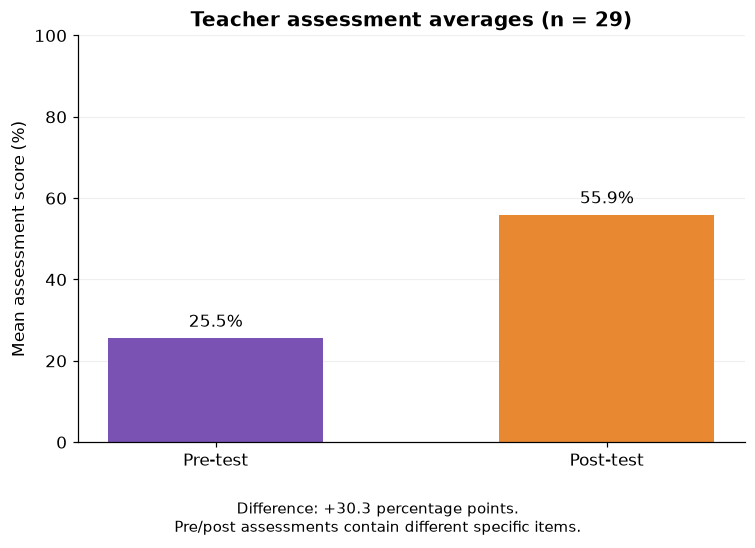

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Pre-test", "Post-test"],
    [pre_mean, post_mean],
    color=[PRE_COLOR, POST_COLOR],
    width=0.55
)

ax.bar_label(
    bars,
    labels=[f"{pre_mean:.1f}%", f"{post_mean:.1f}%"],
    padding=5
)

ax.set_ylim(0, 100)
ax.set_ylabel("Mean assessment score (%)")
ax.set_title(f"Teacher assessment averages (n = {n})")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.5, 0.02,
    f"Difference: {mean_change_pp:+.1f} percentage points.\n"
    "Pre/post assessments contain different specific items.",
    ha="center", fontsize=10
)

fig.tight_layout(rect=[0, 0.10, 1, 1])
save_figure(fig, "01_teachers_pre_post_averages.png")
plt.show()

## 3. Participant Score Changes

Participants are grouped according to whether their post-test total was
higher than, equal to, or lower than their pre-test total.

These categories describe score changes between the two assessments.
They should not be interpreted as definitive changes in individual ability.

,outcome,participants,percent
0,Higher post-test score,22,75.86
1,Unchanged score,6,20.69
2,Lower post-test score,1,3.45


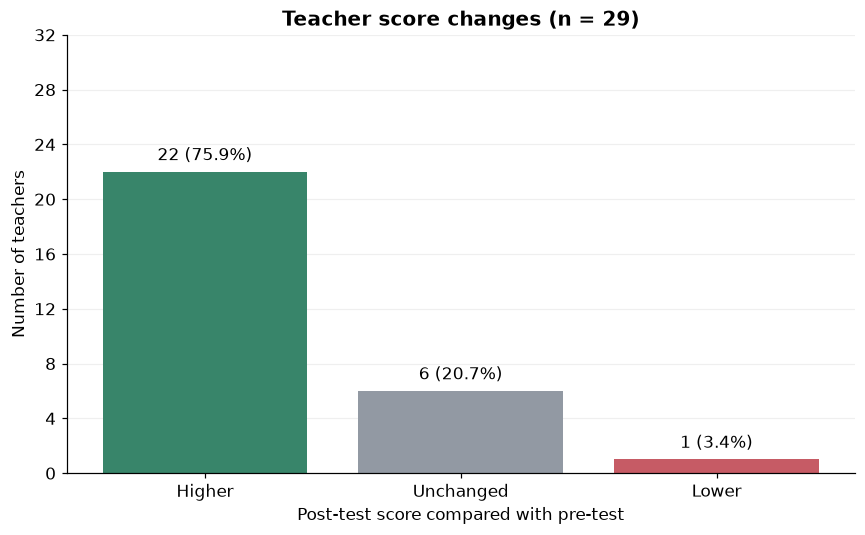

In [6]:
teachers["score_change_group"] = np.select(
    [
        teachers["change_points"].gt(0),
        teachers["change_points"].lt(0)
    ],
    ["Higher post-test score", "Lower post-test score"],
    default="Unchanged score"
)

group_order = [
    "Higher post-test score",
    "Unchanged score",
    "Lower post-test score"
]

change_summary = (
    teachers["score_change_group"]
    .value_counts()
    .reindex(group_order, fill_value=0)
    .rename_axis("outcome")
    .reset_index(name="participants")
)

change_summary["percent"] = (
    change_summary["participants"] / n * 100
)

display(change_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Higher", "Unchanged", "Lower"],
    change_summary["participants"],
    color=["#38856A", "#9299A3", "#C65B65"]
)

ax.bar_label(
    bars,
    labels=[
        f"{count} ({percent:.1f}%)"
        for count, percent in zip(
            change_summary["participants"],
            change_summary["percent"]
        )
    ],
    padding=5
)

ax.set_ylim(0, n + 3)
ax.set_ylabel("Number of teachers")
ax.set_xlabel("Post-test score compared with pre-test")
ax.set_title(f"Teacher score changes (n = {n})")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
save_figure(fig, "02_teachers_score_changes.png")
plt.show()

## 4. Score Distributions

The distribution chart shows how many teachers received each score from
zero to five in each phase.

This complements the averages by showing whether results were concentrated
at particular scores or spread across the assessment scale.

,score,pre_count,post_count
0,0,4,0
1,1,14,5
2,2,10,11
3,3,1,4
4,4,0,3
5,5,0,6


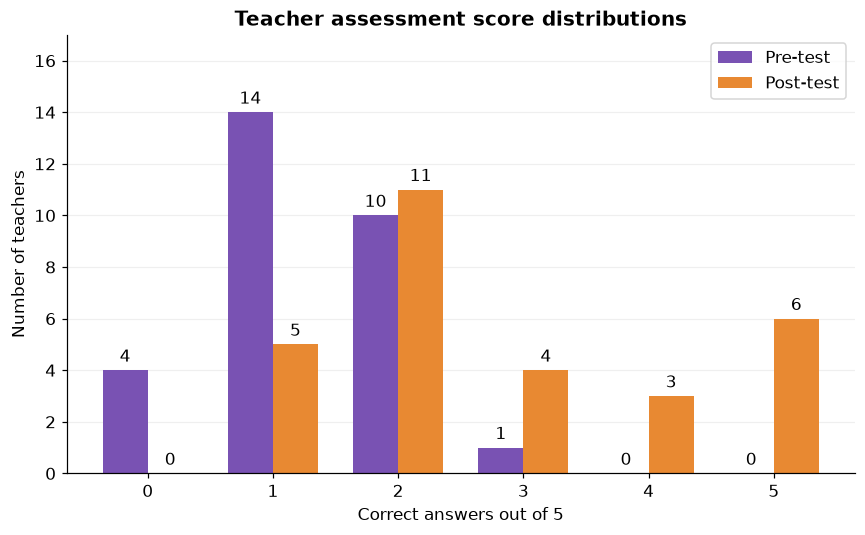

In [7]:
distribution = pd.DataFrame({
    "score": range(6),
    "pre_count": (
        teachers["pre_correct"]
        .value_counts()
        .reindex(range(6), fill_value=0)
        .to_numpy()
    ),
    "post_count": (
        teachers["post_correct"]
        .value_counts()
        .reindex(range(6), fill_value=0)
        .to_numpy()
    )
})

display(distribution)

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(6)
width = 0.36

pre_bars = ax.bar(
    x - width / 2,
    distribution["pre_count"],
    width,
    label="Pre-test",
    color=PRE_COLOR
)

post_bars = ax.bar(
    x + width / 2,
    distribution["post_count"],
    width,
    label="Post-test",
    color=POST_COLOR
)

ax.bar_label(pre_bars, padding=3)
ax.bar_label(post_bars, padding=3)

ax.set_xticks(x)
ax.set_xlabel("Correct answers out of 5")
ax.set_ylabel("Number of teachers")
ax.set_title("Teacher assessment score distributions")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_ylim(
    0,
    max(distribution["pre_count"].max(),
        distribution["post_count"].max()) + 3
)
ax.legend()
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
save_figure(fig, "03_teachers_score_distributions.png")
plt.show()

### Interpretation of Score Distributions

Pre-test scores were concentrated at the lower end: 18 of 29 teachers
(62.1%) scored zero or one out of five. No teacher scored four or five.

Post-test scores were distributed more broadly. Nine teachers (31.0%)
scored four or five, including six who answered all five questions
correctly. No teacher scored zero.

However, 16 teachers (55.2%) still scored one or two on the post-test.
The higher group average therefore coexists with substantial variation
in performance and a continuing need for instructional support.

The median increased from one to two correct answers. These are
descriptive differences between assessments containing different items.

## 5. Question-Level Performance

Each item is labeled with its specific skill and phase.

Teacher pre/post question numbers do not represent identical skills.
Therefore, no question-by-question gain is calculated between phases.

A high correct-answer rate indicates strong performance on that particular
item. One item alone is insufficient to establish mastery of an entire skill.

,phase,question,skill,n_correct,n_answered,correct_rate_pct
0,pre,q1,Decomposition,3,29,10.34
1,pre,q2,Flowchart symbol: Decision (diamond),6,29,20.69
2,pre,q3,Block category: Logic (if/then/else),8,29,27.59
3,pre,q4,Algorithm concept,3,29,10.34
4,pre,q5,Debugging: event handler nesting,17,29,58.62
5,post,q1,Abstraction,9,29,31.03
6,post,q2,Flowchart symbol: Input/Output (parallelogram),16,29,55.17
7,post,q3,Block category: Music (play tone),17,29,58.62
8,post,q4,Loops: forever vs. on start,12,29,41.38
9,post,q5,Debugging: increment vs. set block,27,29,93.10


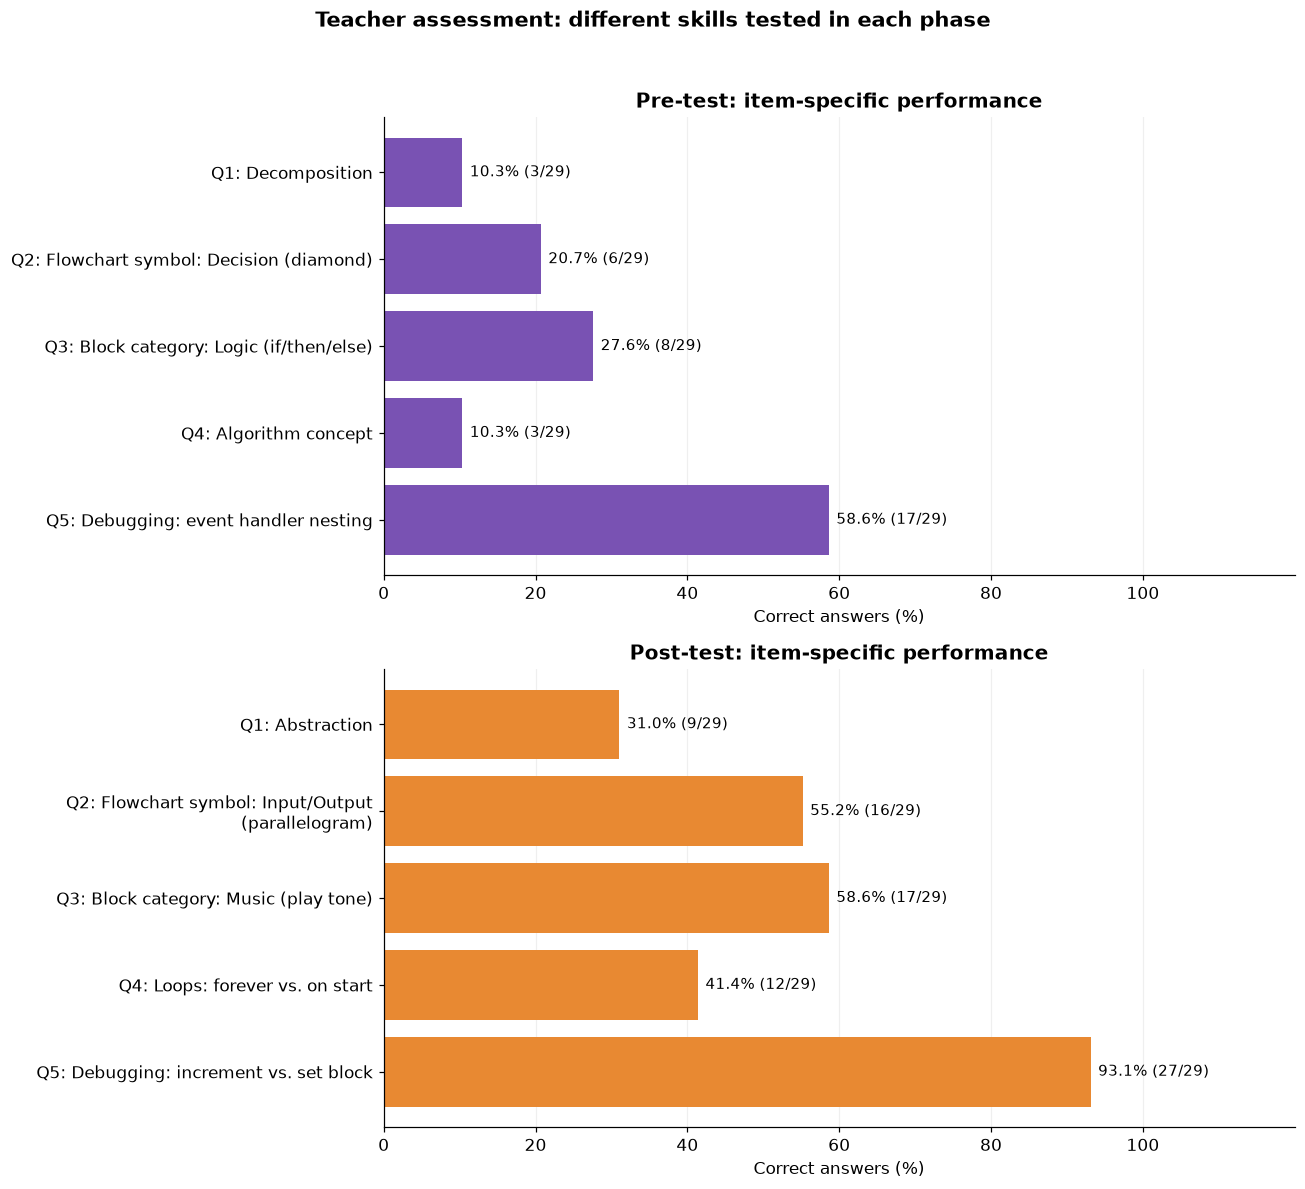

In [8]:
display(
    items[
        ["phase", "question", "skill",
         "n_correct", "n_answered", "correct_rate_pct"]
    ].round(2)
)

fig, axes = plt.subplots(2, 1, figsize=(12, 11))

for ax, phase, color in zip(
    axes,
    ["pre", "post"],
    [PRE_COLOR, POST_COLOR]
):
    phase_items = (
        items.loc[items["phase"].eq(phase)]
        .sort_values("question")
    )

    labels = [
        fill(f"{row.question.upper()}: {row.skill}", width=48)
        for row in phase_items.itertuples()
    ]

    bars = ax.barh(
        labels,
        phase_items["correct_rate_pct"],
        color=color
    )

    ax.bar_label(
        bars,
        labels=[
            f"{row.correct_rate_pct:.1f}% "
            f"({row.n_correct}/{row.n_answered})"
            for row in phase_items.itertuples()
        ],
        padding=5,
        fontsize=10
    )

    ax.invert_yaxis()
    ax.set_xlim(0, 120)
    ax.set_xticks(np.arange(0, 101, 20))
    ax.set_xlabel("Correct answers (%)")
    ax.set_title(f"{phase.title()}-test: item-specific performance")
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.2)

fig.suptitle(
    "Teacher assessment: different skills tested in each phase",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.96])
save_figure(fig, "04_teachers_item_performance.png")
plt.show()

In [9]:
post_items = items.loc[items["phase"].eq("post")].copy()

highest_items = post_items.loc[
    post_items["correct_rate_pct"].eq(
        post_items["correct_rate_pct"].max()
    )
]

lowest_items = post_items.loc[
    post_items["correct_rate_pct"].eq(
        post_items["correct_rate_pct"].min()
    )
]

def describe_items(df):
    return "; ".join(
        f"{row.skill} ({row.correct_rate_pct:.1f}%, "
        f"{row.n_correct}/{row.n_answered})"
        for row in df.itertuples()
    )

counts = change_summary.set_index("outcome")["participants"]

findings_md = f"""
## Teacher Findings

The analysis included **{n} teacher assessment records**.
Recalculated scores matched the workbook values for all records.

The average pre-test score was **{pre_mean:.1f}%**
({teachers['pre_correct'].mean():.2f}/5), compared with
**{post_mean:.1f}%** ({teachers['post_correct'].mean():.2f}/5)
on the post-test. The average difference was
**{mean_change_pp:+.1f} percentage points**.

Of the {n} teachers:
- **{counts['Higher post-test score']}**
  had higher post-test totals.
- **{counts['Unchanged score']}**
  had unchanged totals.
- **{counts['Lower post-test score']}**
  had lower post-test totals.

The highest post-test correct-answer rate was observed for:
**{describe_items(highest_items)}**.

The lowest post-test correct-answer rate was observed for:
**{describe_items(lowest_items)}**.

The lowest-performing post-test item(s) identify possible priorities for
follow-up practice. These results describe performance on individual
questions and do not establish complete mastery or lack of mastery.

Because the teacher assessments contain different specific items,
the total-score difference cannot be interpreted as improvement on
equivalent tests. These results alone also do not establish that the
program caused the observed difference.
"""

display(Markdown(findings_md))


## Teacher Findings

The analysis included **29 teacher assessment records**.
Recalculated scores matched the workbook values for all records.

The average pre-test score was **25.5%**
(1.28/5), compared with
**55.9%** (2.79/5)
on the post-test. The average difference was
**+30.3 percentage points**.

Of the 29 teachers:
- **22**
  had higher post-test totals.
- **6**
  had unchanged totals.
- **1**
  had lower post-test totals.

The highest post-test correct-answer rate was observed for:
**Debugging: increment vs. set block (93.1%, 27/29)**.

The lowest post-test correct-answer rate was observed for:
**Abstraction (31.0%, 9/29)**.

The lowest-performing post-test item(s) identify possible priorities for
follow-up practice. These results describe performance on individual
questions and do not establish complete mastery or lack of mastery.

Because the teacher assessments contain different specific items,
the total-score difference cannot be interpreted as improvement on
equivalent tests. These results alone also do not establish that the
program caused the observed difference.


## 6. Recommendations and Interpretation

### Prioritize Abstraction

Abstraction had the lowest post-test correct-answer rate: 9 of 29
teachers (31.0%). Follow-up activities should give teachers practice
identifying essential information and separating it from unnecessary
details.

For example, present a climate-monitoring scenario and ask which data
are necessary to decide whether a heat alert should be triggered.
Use several follow-up questions to assess understanding.

### Reinforce Program Execution and Loops

The item distinguishing "forever" from "on start" was answered correctly
by 12 teachers (41.4%).

Use short code-tracing activities that ask teachers to predict which
instructions execute once and which repeat. Demonstrate the behavior,
then let participants modify and explain the program.

### Review Flowchart Symbols and Block Categories

Post-test accuracy was 55.2% for the input/output flowchart symbol and
58.6% for the music block category.

Provide brief matching and application exercises connecting symbols
and block categories to their purposes. Review incorrect answer choices
to identify possible misconceptions.

### Extend the Strongest Observed Result

The increment-versus-set debugging item had the highest post-test
accuracy: 27 of 29 teachers (93.1%).

Use this result as a starting point for more varied debugging exercises.
Strong performance on one question does not establish mastery of
debugging as a whole.

### Provide Differentiated Follow-Up Practice

Although 22 teachers had higher post-test totals, 16 still scored no
more than two out of five on the post-test.

Offer guided practice alongside extension activities, using additional
assessment evidence to identify individual support needs.

### Improve Future Assessment Comparability

The teacher pre-test and post-test contain different specific items.
Future assessments should include common items or forms with
established comparability.

The observed 30.34-percentage-point difference describes the change
between these assessment totals. It does not isolate the program's
effect from differences in item difficulty or other influences.

Facilitator observations and participant feedback would help investigate
possible explanations. Confidence, frustration, and classroom teaching
ability were not directly measured by these test scores.

In [10]:
summary.to_csv(
    TABLES / "teachers_score_summary.csv", index=False
)

change_summary.to_csv(
    TABLES / "teachers_change_summary.csv", index=False
)

distribution.to_csv(
    TABLES / "teachers_score_distribution.csv", index=False
)

items.to_csv(
    TABLES / "teachers_item_performance.csv", index=False
)

verification.to_csv(
    TABLES / "teachers_score_verification.csv", index=False
)

(TABLES / "teachers_findings.md").write_text(
    findings_md.strip(),
    encoding="utf-8"
)

print("Saved 4 figures to:", FIGURES)
print("Saved 5 tables and the findings text to:", TABLES)

Saved 4 figures to: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\figures\teachers
Saved 5 tables and the findings text to: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\tables\teachers
